# Challenge 3: entrenamiento y evaluación de una CNN

**Grupo 1 — Machine Learning, UPCH, 2026-II**

- César Alejandro Aarón Apcho Meneses
- Paola Andrea Centeno Bazán
- Anderson Josué Delerna Infantes
- Jimena Natalia Vega Sánchez

**Docente:** Yannick Patrick Carrasco Merma.

En este cuaderno entrenamos y comparamos cinco configuraciones de una red neuronal convolucional para la competición [TNM112-Lab2 (2026)](https://www.kaggle.com/competitions/tnm-112-lab-2-2026). Utilizamos los archivos oficiales de entrenamiento y validación; el conjunto de prueba se reserva para generar predicciones.

**Estado de esta versión:** ejecutada completamente en Kaggle con los tres archivos oficiales. Las ocho celdas de código conservan sus salidas reales. La ejecución se completó el 15 de noviembre de 2026 (hora de Lima), en CPU, y duró 39 min 23 s. La mejor Balanced Accuracy de validación fue 0,748689 con `02_dropout`. No se realizaron envíos a la competición. [Consultar ejecución original](https://www.kaggle.com/code/cesarapcho/challenge-3-upch-grupo-1-cnn-pcam?scriptVersionId=370083154).

El modelo utiliza imágenes de **32 × 32 × 3**. No se necesitan pesos preentrenados ni datos externos. Una sola cuenta realiza los envíos y los cuatro integrantes figuran como autores académicos, según la indicación del docente.


## 1. Cómo ejecutar el cuaderno

**Google Colab:** seleccionar una GPU en Entorno de ejecución → Cambiar tipo de entorno. Descargar y extraer `train.h5`, `valid.h5` y `test_x.h5` desde Kaggle, colocarlos en `Mi unidad/Challenge3/data` y seleccionar Ejecutar todas. El acceso a Drive se solicita en la siguiente sección. Los resultados se guardan en `Mi unidad/Challenge3/results/cnn`.

**Kaggle:** importar este `.ipynb`, activar una GPU y añadir los datos de la competición desde Add Input. El cuaderno busca los tres HDF5 dentro de `/kaggle/input`. Los resultados se guardan en `/kaggle/working/results/cnn`. Usar Save Version → Save & Run All para conservar la ejecución.

**Jupyter local:** instalar `requirements-cnn.txt`, colocar los HDF5 en `data/` y ejecutar las celdas en orden. También se puede definir `CHALLENGE3_DATOS` con la ruta de la carpeta.

El tiempo depende de la GPU y de la parada temprana. Se entrenan cinco configuraciones distintas con todos los ejemplos. El cuaderno genera archivos; el envío a la competición se realiza por separado.


In [1]:
import importlib.util
import subprocess
import sys

paquetes = {'tensorflow':'tensorflow>=2.16,<2.22', 'h5py':'h5py>=3.8,<4',
            'numpy':'numpy>=1.26,<3', 'pandas':'pandas>=2,<4',
            'matplotlib':'matplotlib>=3.7,<4', 'sklearn':'scikit-learn>=1.4,<2'}
faltantes = [paquete for modulo, paquete in paquetes.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *faltantes])
print('Dependencias disponibles.')


Dependencias disponibles.


In [2]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import gc
import json
import hashlib
import platform
import time
from pathlib import Path
from datetime import datetime, timezone

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (balanced_accuracy_score, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
gpu = tf.config.list_physical_devices('GPU')
for dispositivo in gpu:
    tf.config.experimental.set_memory_growth(dispositivo, True)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    pass
print('Python:', platform.python_version())
print('TensorFlow:', tf.__version__)
print('GPU:', gpu if gpu else 'No disponible; el entrenamiento usará CPU.')

ARCHIVOS = ('train.h5', 'valid.h5', 'test_x.h5')
ruta_configurada = os.environ.get('CHALLENGE3_DATOS')
if ruta_configurada:
    DATOS = Path(ruta_configurada).expanduser()
elif Path('/kaggle/input').is_dir():
    candidatos = [p.parent for p in Path('/kaggle/input').rglob('train.h5')
                  if all((p.parent / n).is_file() for n in ARCHIVOS)]
    if len(candidatos) != 1:
        raise FileNotFoundError('Añadir los datos oficiales de la competición. '
                                'Si hay varias copias, definir CHALLENGE3_DATOS.')
    DATOS = candidatos[0]
elif 'google.colab' in sys.modules or os.environ.get('COLAB_RELEASE_TAG'):
    from google.colab import drive
    drive.mount('/content/drive')
    DATOS = Path('/content/drive/MyDrive/Challenge3/data')
else:
    candidatos = [p.resolve() for p in (Path('data'), Path('../data'))
                  if all((p / n).is_file() for n in ARCHIVOS)]
    if len(candidatos) != 1:
        raise FileNotFoundError('Colocar los HDF5 en data/ o definir CHALLENGE3_DATOS.')
    DATOS = candidatos[0]

for nombre in ARCHIVOS:
    if not (DATOS / nombre).is_file():
        raise FileNotFoundError(f'Falta el archivo {DATOS / nombre}')

if Path('/kaggle/working').is_dir():
    SALIDA = Path('/kaggle/working/results/cnn')
elif str(DATOS).startswith('/content/drive/'):
    SALIDA = DATOS.parent / 'results/cnn'
else:
    SALIDA = Path('results/cnn') if Path('data').is_dir() else Path('../results/cnn')
SALIDA.mkdir(parents=True, exist_ok=True)
print('Datos:', DATOS)
print('Resultados:', SALIDA.resolve())


I0000 00:00:1794792183.520791      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794792200.380615      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Python: 3.13.18
TensorFlow: 2.21.0
GPU: No disponible; el entrenamiento usará CPU.
Datos: /kaggle/input/competitions/tnm-112-lab-2-2026
Resultados: /kaggle/working/results/cnn


E0000 00:00:1794792205.745630      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Carga y comprobación de los archivos oficiales

Se comprueba el número de ejemplos, las dimensiones, el tipo de los píxeles y las etiquetas. Los datos se conservan en `uint8` para reducir el uso de memoria; la división entre 255 se realiza dentro de cada CNN. Se utilizan los conjuntos oficiales, sin volver a mezclarlos entre entrenamiento y validación.


In [3]:
def cargar(nombre, cantidad, etiquetado=True):
    with h5py.File(DATOS / nombre, 'r') as archivo:
        x = archivo['x'][:]
        y = archivo['y'][:].reshape(-1) if etiquetado else None
    if x.shape != (cantidad, 32, 32, 3) or x.dtype != np.uint8:
        raise ValueError(f'Estructura inesperada en {nombre}: {x.shape}, {x.dtype}')
    if etiquetado and (len(y) != cantidad or set(np.unique(y)) != {0, 1}):
        raise ValueError(f'Etiquetas inesperadas en {nombre}')
    return x, y

x_train, y_train = cargar('train.h5', 100000)
x_valid, y_valid = cargar('valid.h5', 32768)
resumen = []
for nombre, x, y in [('train.h5', x_train, y_train), ('valid.h5', x_valid, y_valid)]:
    resumen.append({'archivo':nombre, 'dimensiones':str(x.shape),
                    'clase_0':int(np.sum(y == 0)), 'clase_1':int(np.sum(y == 1))})
display(pd.DataFrame(resumen))
pd.DataFrame(resumen).to_csv(SALIDA / 'datos_utilizados.csv', index=False)
with h5py.File(DATOS / 'test_x.h5', 'r') as archivo:
    if archivo['x'].shape != (32768, 32, 32, 3) or archivo['x'].dtype != np.uint8:
        raise ValueError('El archivo de prueba no tiene la estructura esperada.')
    print('Prueba:', archivo['x'].shape, 'Claves:', list(archivo.keys()))


,archivo,dimensiones,clase_0,clase_1
0,train.h5,"(100000, 32, 32, 3)",49964,50036
1,valid.h5,"(32768, 32, 32, 3)",16399,16369


Prueba: (32768, 32, 32, 3) Claves: ['x']


## 3. Modelo y experimentos

Una CNN aplica filtros sobre regiones de la imagen para aprender patrones visuales. Se relaciona con las redes neuronales estudiadas en clase mediante sus pesos, activaciones, retropropagación y optimización. Aquí se utilizan convoluciones, ReLU, MaxPooling y una salida sigmoide. La pérdida es entropía cruzada binaria y el optimizador es Adam.

Se comparan cinco configuraciones: una base, otra con Dropout, otra con aumento de datos, otra con mayor profundidad y una quinta con Batch Normalization. Son cambios propuestos; su utilidad se determina con los resultados de validación. Todos los modelos utilizan el mismo umbral 0,5 y la misma semilla.

**Balanced Accuracy** es el promedio del recall de las dos clases. Es la métrica oficial. Aunque las etiquetas observadas están casi equilibradas, se mantiene esta métrica para evaluar cada configuración. Un valor de validación mayor que 0,5 no garantiza una puntuación equivalente en Kaggle.


In [4]:
EXPERIMENTOS = [
    dict(nombre='01_base', filtros=[16,32], dropout=0.0, aumento=False,
         batchnorm=False, lr=0.001, batch=256, epocas=10),
    dict(nombre='02_dropout', filtros=[16,32], dropout=0.3, aumento=False,
         batchnorm=False, lr=0.001, batch=256, epocas=12),
    dict(nombre='03_aumento', filtros=[16,32], dropout=0.3, aumento=True,
         batchnorm=False, lr=0.001, batch=256, epocas=12),
    dict(nombre='04_profunda', filtros=[32,64,128], dropout=0.3, aumento=True,
         batchnorm=False, lr=0.001, batch=256, epocas=15),
    dict(nombre='05_batchnorm', filtros=[32,64,128], dropout=0.3, aumento=True,
         batchnorm=True, lr=0.0005, batch=256, epocas=15),
]
display(pd.DataFrame(EXPERIMENTOS))

def crear_modelo(config):
    entradas = keras.Input(shape=(32,32,3), dtype='uint8')
    x = layers.Rescaling(1./255)(entradas)
    if config['aumento']:
        x = layers.RandomFlip('horizontal_and_vertical', seed=SEMILLA)(x)
        x = layers.RandomRotation(0.1, seed=SEMILLA+1)(x)
    for filtros in config['filtros']:
        x = layers.Conv2D(filtros, 3, padding='same',
                          use_bias=not config['batchnorm'])(x)
        if config['batchnorm']:
            x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(32, activation='relu')(x)
    if config['dropout']:
        x = layers.Dropout(config['dropout'], seed=SEMILLA+2)(x)
    salidas = layers.Dense(1, activation='sigmoid')(x)
    modelo = keras.Model(entradas, salidas, name=config['nombre'])
    modelo.compile(optimizer=keras.optimizers.Adam(config['lr']),
                   loss='binary_crossentropy', metrics=['accuracy'])
    return modelo

keras.backend.clear_session()
crear_modelo(EXPERIMENTOS[0]).summary()


,nombre,filtros,dropout,aumento,batchnorm,lr,batch,epocas
0,01_base,"[16, 32]",0.0,False,False,0.0010,256,10
1,02_dropout,"[16, 32]",0.3,False,False,0.0010,256,12
2,03_aumento,"[16, 32]",0.3,True,False,0.0010,256,12
3,04_profunda,"[32, 64, 128]",0.3,True,False,0.0010,256,15
4,05_batchnorm,"[32, 64, 128]",0.3,True,True,0.0005,256,15


Model: "01_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,177 (24.13 KB)

 Trainable params: 6,177 (24.13 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Entrenamiento y selección con validación

Cada época se evalúa sobre validación. Se conserva la época con mayor Balanced Accuracy y se detiene el entrenamiento si esa métrica deja de mejorar durante tres épocas. Las imágenes de prueba no intervienen en la selección de los modelos.

Si una ejecución se interrumpe, se puede volver a iniciar. Solo se reutilizan experimentos que tengan modelo, historial y métricas terminados, con la misma configuración, versión de código y firma de los datos. Para repetir todo desde cero se establece `REUTILIZAR_COMPLETADOS = False`.


In [5]:
VERSION_CODIGO = 'cnn-challenge3-v1'
REUTILIZAR_COMPLETADOS = True

def firma_archivo(ruta):
    h = hashlib.sha256()
    with ruta.open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(8*1024*1024), b''):
            h.update(bloque)
    return h.hexdigest()

firmas = {nombre:firma_archivo(DATOS / nombre) for nombre in ARCHIVOS}
entorno = {'python':platform.python_version(), 'tensorflow':tf.__version__,
           'numpy':np.__version__, 'pandas':pd.__version__, 'h5py':h5py.__version__}
manifiesto = dict(codigo=VERSION_CODIGO, semilla=SEMILLA, archivos_sha256=firmas,
                  entorno=entorno, experimentos=EXPERIMENTOS)
(SALIDA / 'configuracion.json').write_text(json.dumps(manifiesto, indent=2), encoding='utf-8')

def crear_dataset(x, y, batch, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y.astype('float32')))
    if entrenamiento:
        ds = ds.shuffle(min(len(x), 10000), seed=SEMILLA, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(2)

class BalancedAccuracyValidacion(keras.callbacks.Callback):
    def __init__(self, datos_validacion, etiquetas):
        super().__init__()
        self.datos_validacion = datos_validacion
        self.etiquetas = etiquetas
    def on_epoch_end(self, epoch, logs=None):
        probabilidades = self.model.predict(self.datos_validacion, verbose=0).reshape(-1)
        valor = float(balanced_accuracy_score(self.etiquetas, probabilidades >= 0.5))
        if logs is not None:
            logs['val_balanced_accuracy'] = valor
        print(f' — val_balanced_accuracy: {valor:.5f}')

def metricas(y, probabilidades):
    pred = (probabilidades >= 0.5).astype('uint8')
    return {'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
            'accuracy':float(accuracy_score(y,pred)),
            'precision':float(precision_score(y,pred,zero_division=0)),
            'recall':float(recall_score(y,pred,zero_division=0)),
            'f1':float(f1_score(y,pred,zero_division=0)),
            'roc_auc':float(roc_auc_score(y,probabilidades))}

filas = []
for config in EXPERIMENTOS:
    carpeta = SALIDA / config['nombre']
    carpeta.mkdir(exist_ok=True)
    ruta_modelo = carpeta / 'mejor_modelo.keras'
    ruta_metricas = carpeta / 'metricas.json'
    firma = dict(codigo=VERSION_CODIGO, config=config, semilla=SEMILLA,
                 archivos_sha256=firmas, entorno=entorno)
    terminado = all((carpeta/n).is_file() for n in
                    ['mejor_modelo.keras','metricas.json','historial.csv',
                     'validacion.csv','firma.json'])
    if REUTILIZAR_COMPLETADOS and terminado:
        terminado = json.loads((carpeta/'firma.json').read_text()) == firma
    if REUTILIZAR_COMPLETADOS and terminado:
        fila = json.loads(ruta_metricas.read_text())
        print('Experimento completado previamente:', config['nombre'])
    else:
        keras.backend.clear_session()
        gc.collect()
        keras.utils.set_random_seed(SEMILLA)
        modelo = crear_modelo(config)
        ds_train = crear_dataset(x_train,y_train,config['batch'],True)
        ds_valid = crear_dataset(x_valid,y_valid,config['batch'])
        callbacks = [
            BalancedAccuracyValidacion(ds_valid,y_valid),
            keras.callbacks.ModelCheckpoint(str(ruta_modelo),monitor='val_balanced_accuracy',
                                            mode='max',save_best_only=True),
            keras.callbacks.EarlyStopping(monitor='val_balanced_accuracy',mode='max',patience=3),
            keras.callbacks.TerminateOnNaN(),
        ]
        inicio = time.monotonic()
        historial = modelo.fit(ds_train,validation_data=ds_valid,
                              epochs=config['epocas'],callbacks=callbacks,verbose=2)
        pd.DataFrame(historial.history).to_csv(carpeta/'historial.csv',index=False)
        modelo = keras.models.load_model(ruta_modelo)
        p_valid = modelo.predict(ds_valid,verbose=0).reshape(-1)
        if not np.isfinite(p_valid).all():
            raise ValueError('Predicciones de validación no finitas.')
        fila = dict(experimento=config['nombre'],**metricas(y_valid,p_valid),
                    epocas_ejecutadas=len(historial.epoch),
                    mejor_epoca=int(np.argmax(historial.history['val_balanced_accuracy']))+1,
                    segundos=round(time.monotonic()-inicio,2))
        pd.DataFrame({'indice_validacion':np.arange(len(y_valid)), 'clase_real':y_valid,
                      'probabilidad_1':p_valid,'clase_predicha':(p_valid>=0.5).astype('uint8')}
                     ).to_csv(carpeta/'validacion.csv',index=False)
        ruta_metricas.write_text(json.dumps(fila,indent=2),encoding='utf-8')
        (carpeta/'firma.json').write_text(json.dumps(firma,indent=2),encoding='utf-8')
        del modelo,ds_train,ds_valid
    filas.append(fila)
    pd.DataFrame(filas).to_csv(SALIDA/'metricas_validacion.csv',index=False)

comparacion = pd.DataFrame(filas).sort_values('balanced_accuracy',ascending=False)
display(comparacion)
MEJOR = str(comparacion.iloc[0]['experimento'])
print('Configuración seleccionada con validación:',MEJOR)


Epoch 1/10
 — val_balanced_accuracy: 0.74384
391/391 - 43s - 110ms/step - accuracy: 0.7392 - loss: 0.5456 - val_accuracy: 0.7439 - val_loss: 0.5197 - val_balanced_accuracy: 0.7438
Epoch 2/10
 — val_balanced_accuracy: 0.74847
391/391 - 36s - 93ms/step - accuracy: 0.7622 - loss: 0.5040 - val_accuracy: 0.7485 - val_loss: 0.5115 - val_balanced_accuracy: 0.7485
Epoch 3/10
 — val_balanced_accuracy: 0.74757
391/391 - 41s - 104ms/step - accuracy: 0.7650 - loss: 0.4970 - val_accuracy: 0.7476 - val_loss: 0.5092 - val_balanced_accuracy: 0.7476
Epoch 4/10
 — val_balanced_accuracy: 0.74518
391/391 - 36s - 93ms/step - accuracy: 0.7686 - loss: 0.4920 - val_accuracy: 0.7452 - val_loss: 0.5183 - val_balanced_accuracy: 0.7452
Epoch 5/10
 — val_balanced_accuracy: 0.74663
391/391 - 38s - 98ms/step - accuracy: 0.7685 - loss: 0.4914 - val_accuracy: 0.7467 - val_loss: 0.5138 - val_balanced_accuracy: 0.7466
Epoch 1/12
 — val_balanced_accuracy: 0.73775
391/391 - 39s - 99ms/step - accuracy: 0.7310 - loss: 0.554

,experimento,balanced_accuracy,accuracy,precision,recall,f1,roc_auc,epocas_ejecutadas,mejor_epoca,segundos
1,02_dropout,0.748689,0.748718,0.765347,0.716721,0.740236,0.831596,5,2,191.38
0,01_base,0.748465,0.748474,0.753004,0.738836,0.745853,0.828812,5,2,198.44
2,03_aumento,0.708144,0.708282,0.797848,0.557212,0.656163,0.788403,5,2,223.60
3,04_profunda,0.698728,0.698853,0.772945,0.562343,0.651036,0.785630,4,1,454.23
4,05_batchnorm,0.689939,0.690186,0.910797,0.421040,0.575869,0.863333,7,4,1167.87


Configuración seleccionada con validación: 02_dropout


## 5. Curvas de aprendizaje y matriz de confusión

Las curvas permiten revisar la diferencia entre entrenamiento y validación. La matriz muestra aciertos y errores del mejor modelo según validación. Estas cifras corresponden únicamente al conjunto de validación; no representan una puntuación de Kaggle.


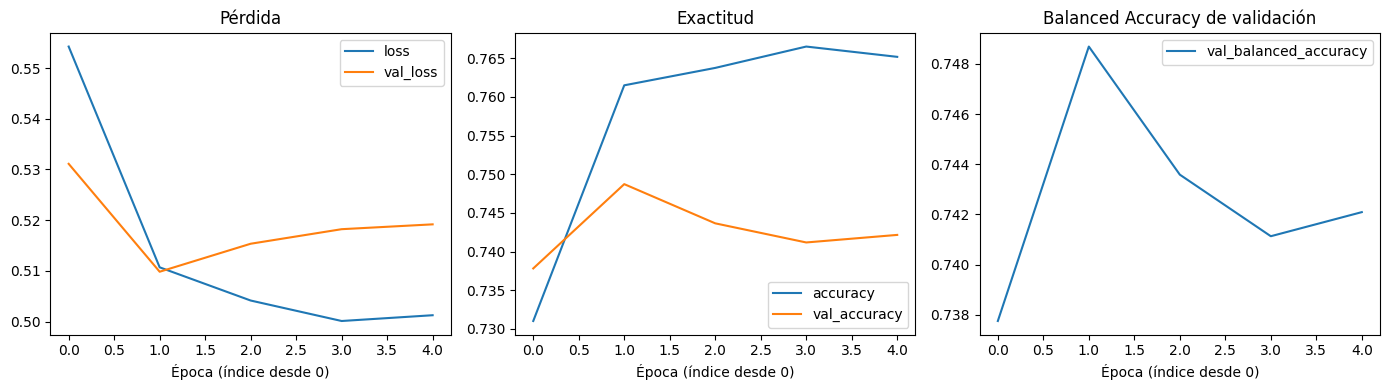

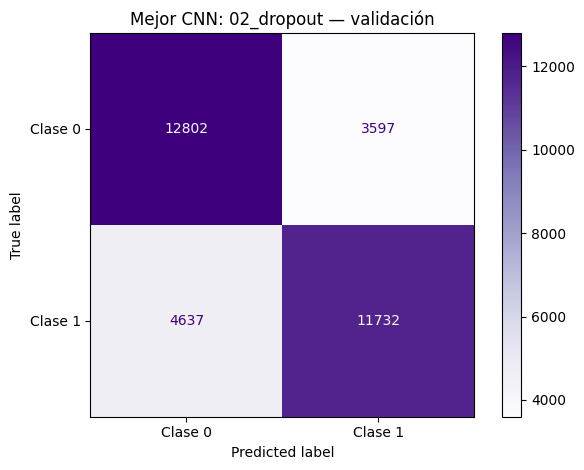

Balanced Accuracy base: 0.74847
Balanced Accuracy seleccionada: 0.74869
Diferencia frente a base: +0.00022


In [6]:
historia = pd.read_csv(SALIDA/MEJOR/'historial.csv')
fig,ejes = plt.subplots(1,3,figsize=(14,4))
historia[['loss','val_loss']].plot(ax=ejes[0],title='Pérdida')
historia[['accuracy','val_accuracy']].plot(ax=ejes[1],title='Exactitud')
historia[['val_balanced_accuracy']].plot(ax=ejes[2],title='Balanced Accuracy de validación')
for eje in ejes:
    eje.set_xlabel('Época (índice desde 0)')
fig.tight_layout()
fig.savefig(SALIDA/'curvas_aprendizaje.png',dpi=160)
plt.show()

validacion = pd.read_csv(SALIDA/MEJOR/'validacion.csv')
matriz = confusion_matrix(validacion['clase_real'],validacion['clase_predicha'],labels=[0,1])
ConfusionMatrixDisplay(matriz,display_labels=['Clase 0','Clase 1']).plot(cmap='Purples',values_format='d')
plt.title(f'Mejor CNN: {MEJOR} — validación')
plt.tight_layout()
plt.savefig(SALIDA/'matriz_confusion.png',dpi=160)
plt.show()
pd.DataFrame(matriz,index=['real_0','real_1'],columns=['pred_0','pred_1']).to_csv(SALIDA/'matriz_confusion.csv')

base = comparacion.set_index('experimento').loc['01_base','balanced_accuracy']
mejor_fila = comparacion.iloc[0]
print(f'Balanced Accuracy base: {base:.5f}')
print(f'Balanced Accuracy seleccionada: {mejor_fila.balanced_accuracy:.5f}')
print(f'Diferencia frente a base: {mejor_fila.balanced_accuracy-base:+.5f}')


## 6. Predicciones y archivo de entrega

La evaluación oficial solicita `ID,Class`, con clases 0 o 1. El HDF5 no contiene identificadores. El ejemplo oficial comienza por 1, por lo que se construyen **candidatos** con ID consecutivos desde 1, conservando el orden original de `test_x.h5`.

**Antes de usar los candidatos como entrega:** comprobar la correspondencia de los ID con las indicaciones o el notebook de referencia del organizador. Solo después cambiar `IDS_CONFIRMADOS` a `True`. Si no se han confirmado, el cuaderno guarda archivos con prefijo `candidato_` y no genera un archivo llamado `submission.csv`. El registro indica exactamente qué supuesto se utilizó.

Se generan candidatos de las cinco configuraciones para poder documentar cambios entre experimentos. Cinco archivos generados no equivalen a cinco envíos válidos: Kaggle debe aceptar y puntuar cada envío por encima de la predicción aleatoria.


In [7]:
IDS_CONFIRMADOS = False
ID_INICIAL = 1
FUENTE_IDS = 'Ejemplo de la página Evaluation; correspondencia completa pendiente de confirmar.'

def construir_csv(ids, clases, destino):
    clases = np.asarray(clases).reshape(-1)
    ids = np.asarray(ids).reshape(-1)
    if len(ids)!=32768 or len(clases)!=len(ids):
        raise ValueError('Debe existir una predicción para cada una de las 32768 imágenes.')
    if len(np.unique(ids))!=len(ids) or not set(np.unique(clases)).issubset({0,1}):
        raise ValueError('Identificadores duplicados o clases diferentes de 0/1.')
    tabla = pd.DataFrame({'ID':ids,'Class':clases.astype('uint8')})
    if tabla.isna().any().any():
        raise ValueError('El archivo contiene datos faltantes.')
    tabla.to_csv(destino,index=False)
    leido = pd.read_csv(destino)
    if list(leido.columns)!=['ID','Class'] or not leido.equals(tabla.astype(leido.dtypes)):
        raise ValueError('El CSV guardado no coincide con las predicciones.')
    return tabla

if 'x_train' in globals():
    del x_train
gc.collect()
ids = np.arange(ID_INICIAL,ID_INICIAL+32768,dtype=np.int64)
archivos_generados = []
for config in EXPERIMENTOS:
    nombre = config['nombre']
    keras.backend.clear_session()
    modelo = keras.models.load_model(SALIDA/nombre/'mejor_modelo.keras')
    probabilidades = []
    with h5py.File(DATOS/'test_x.h5','r') as archivo:
        for inicio in range(0,32768,512):
            lote = archivo['x'][inicio:inicio+512]
            probabilidades.append(modelo(lote,training=False).numpy().reshape(-1))
    p_test = np.concatenate(probabilidades)
    if not np.isfinite(p_test).all() or not ((p_test>=0)&(p_test<=1)).all():
        raise ValueError(f'Probabilidades inválidas en {nombre}')
    prefijo = 'submission' if IDS_CONFIRMADOS else 'candidato'
    destino = SALIDA/f'{prefijo}_{nombre}.csv'
    tabla = construir_csv(ids,(p_test>=0.5).astype('uint8'),destino)
    pd.DataFrame({'indice_test':np.arange(32768),'probabilidad_1':p_test}).to_csv(
        SALIDA/nombre/'probabilidades_test.csv',index=False)
    archivos_generados.append({'experimento':nombre,'archivo':destino.name,
        'filas':len(tabla),'ids_confirmados':IDS_CONFIRMADOS,
        'sha256':firma_archivo(destino)})
    if nombre==MEJOR:
        destino_mejor = SALIDA/('submission.csv' if IDS_CONFIRMADOS else 'candidato_mejor_modelo.csv')
        construir_csv(ids,(p_test>=0.5).astype('uint8'),destino_mejor)
    del modelo

pd.DataFrame(archivos_generados).to_csv(SALIDA/'archivos_generados.csv',index=False)
(SALIDA/'criterio_ids.json').write_text(json.dumps(dict(confirmados=IDS_CONFIRMADOS,
    id_inicial=ID_INICIAL,fuente=FUENTE_IDS,orden='orden original de test_x.h5'),indent=2),encoding='utf-8')
display(pd.read_csv(destino_mejor).head())
print('Archivo seleccionado:',destino_mejor)
print('IDs confirmados:',IDS_CONFIRMADOS)


,ID,Class
0,1,0
1,2,0
2,3,1
3,4,1
4,5,1


Archivo seleccionado: /kaggle/working/results/cnn/candidato_mejor_modelo.csv
IDs confirmados: False


## 7. Registro del trabajo y entrega

La cuenta delegada debe incluir los cuatro integrantes en la descripción del notebook de Kaggle. Se conserva la lista de autores de este cuaderno. Según la indicación del docente, no se requiere incorporar a las cuatro cuentas a un equipo de competición.

Después de cada envío, registrar la fecha, el experimento, el nombre del archivo, la puntuación y el enlace o captura del resultado. La puntuación pública depende de una parte del conjunto de prueba; el modelo se selecciona con validación y no se ajusta repetidamente a partir del leaderboard.

Para actualizar GitHub con las salidas visibles: en Colab guardar el cuaderno ejecutado mediante Archivo → Guardar una copia en GitHub, o descargar el `.ipynb` y reemplazar este archivo. En Kaggle descargar la versión terminada. Subir también `metricas_validacion.csv`, las figuras y el resumen; los modelos entrenados se conservan en Drive o en los outputs de Kaggle por su tamaño.


In [8]:
autores = ['César Alejandro Aarón Apcho Meneses','Paola Andrea Centeno Bazán',
           'Anderson Josué Delerna Infantes','Jimena Natalia Vega Sánchez']
estado = dict(estado='entrenamiento_y_predicciones_completados',
    finalizacion_utc=datetime.now(timezone.utc).isoformat(),autores=autores,
    mejor_experimento=MEJOR,metricas_mejor=mejor_fila.to_dict(),
    ids_confirmados=IDS_CONFIRMADOS,envios_a_kaggle_realizados_por_este_cuaderno=0,
    nota='La validez y puntuación de los envíos se comprueban por separado en Kaggle.')
(SALIDA/'estado_ejecucion.json').write_text(json.dumps(estado,indent=2,ensure_ascii=False),encoding='utf-8')
texto = ('# Resultados de la CNN\n\n'
    + 'Ejecución finalizada: '+estado['finalizacion_utc']+'\n\n'
    + 'Configuración seleccionada con validación: **'+MEJOR+'**.\n\n'
    + comparacion.to_csv(index=False)+'\n'
    + 'Identificadores confirmados: '+str(IDS_CONFIRMADOS)+'.\n'
    + 'Envíos realizados por este cuaderno: 0. La puntuación de Kaggle se registra después de enviar cada archivo.\n')
(SALIDA/'RESUMEN_RESULTADOS.md').write_text(texto,encoding='utf-8')
print('Entrenamiento, evaluación y exportación terminados.')
print('Resultados:',SALIDA.resolve())
display(comparacion[['experimento','balanced_accuracy','accuracy','f1','roc_auc']])


Entrenamiento, evaluación y exportación terminados.
Resultados: /kaggle/working/results/cnn


,experimento,balanced_accuracy,accuracy,f1,roc_auc
1,02_dropout,0.748689,0.748718,0.740236,0.831596
0,01_base,0.748465,0.748474,0.745853,0.828812
2,03_aumento,0.708144,0.708282,0.656163,0.788403
3,04_profunda,0.698728,0.698853,0.651036,0.785630
4,05_batchnorm,0.689939,0.690186,0.575869,0.863333


## Referencias

- [Competición y evaluación oficial: TNM112-Lab2 (2026)](https://www.kaggle.com/competitions/tnm-112-lab-2-2026/overview/evaluation).
- [TensorFlow: clasificación de imágenes](https://www.tensorflow.org/tutorials/images/classification).
- [Keras: ModelCheckpoint](https://keras.io/api/callbacks/model_checkpoint/).
- [Scikit-learn: Balanced Accuracy](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html).
- Veeling et al., [Rotation Equivariant CNNs for Digital Pathology](https://arxiv.org/abs/1806.03962), 2018.
